In [53]:
import numpy as np
import matplotlib.pyplot as plt
from random import randint

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"

def normalize(input_array):
    min_val = np.min(input_array)
    max_val = np.max(input_array)
    
    return (input_array - min_val) / (max_val - min_val)

def standardize(input_array):
    return (input_array - np.mean(input_array)) / np.std(input_array)
def mimic_standardize(input_array, mimic_mean, mimic_std):
    return (input_array - mimic_mean) / mimic_std

# data import

data_in = np.genfromtxt("rnn_input_z.csv", delimiter=",", dtype=np.float32)[:, :1000]
data_out = np.genfromtxt("rnn_output_z.csv", delimiter=",", dtype=np.float32)[:, :3000]
nb_data = data_in.shape[0]


In [67]:
train_size = int(0.7*nb_data)
val_size = int(0.15*nb_data)
test_size = int(0.15*nb_data)

az_data = mimic_standardize(data_out[:, 2::3], -9.47285652160644, 21.485586166381836)
input_data = mimic_standardize(data_in, 0.012267900630831718, 1.7312034368515015)

In [ ]:
import onnx
import onnxruntime

onnx_model = onnx.load("rnn_model.onnx")
onnx.checker.check_model(onnx_model)

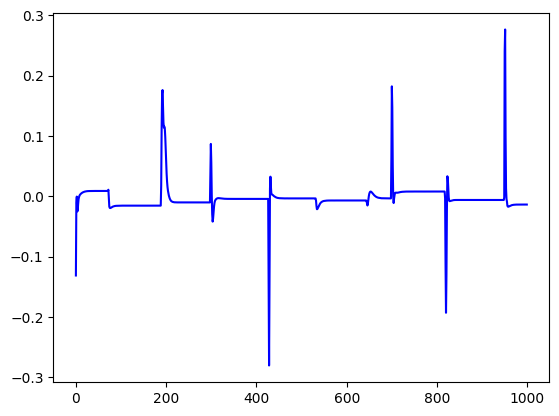

In [ ]:
train_rand_idx = randint(0, train_size-1)
test_rand_idx = randint(train_size+val_size, nb_data-1)

onnx_inputs = [input_data[train_rand_idx].reshape(1, 1000, 1)]

ort_session = onnxruntime.InferenceSession(
    "./rnn_model.onnx", providers=["CPUExecutionProvider"]
)

onnxruntime_input = {input_arg.name: input_value for input_arg, input_value in zip(ort_session.get_inputs(), onnx_inputs)}

# ONNX Runtime returns a list of outputs
onnxruntime_outputs = ort_session.run(None, onnxruntime_input)[0]

# plt.plot(data_in[rand_idx].reshape(1000), c="blue")
#plt.plot(az_data[test_rand_idx], c="green")
#plt.plot(onnxruntime_outputs[:, :][0], c="red")
plt.plot(az_data[train_rand_idx] - onnxruntime_outputs[:, :][0][:, 0], c="blue")